In [2]:
# 04 - Keşifsel Veri Analizi ve İş Analizi

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


PROJECT_DIR = Path.cwd().parent

OUTPUT_DIR = PROJECT_DIR / "ciktilar"
ANALIZ_DIR = OUTPUT_DIR / "analiz"


ANALIZ_DOSYASI = ANALIZ_DIR / "musteri_analiz_tablosu.csv"

print("Proje dizini:", PROJECT_DIR)
print("Analiz dosyası:", ANALIZ_DOSYASI)
print("Dosya mevcut mu?", ANALIZ_DOSYASI.exists())


musteri_analiz = pd.read_csv(
    ANALIZ_DOSYASI,
    encoding="utf-8-sig"
)

tarih_kolonlari = [
    "son_servis_tarihi",
    "ilk_geri_bildirim_tarihi",
    "son_geri_bildirim_tarihi"
]

for kolon in tarih_kolonlari:
    musteri_analiz[kolon] = pd.to_datetime(
        musteri_analiz[kolon],
        errors="coerce"
    )

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("\n--- EDA Veri Kontrolü ---")
print("Tablo boyutu:", musteri_analiz.shape)
print("Tekil müşteri:", musteri_analiz["musteri_id"].nunique())

print("\nChurn dağılımı:")
print(musteri_analiz["churn"].value_counts().sort_index())

print("\nEksik değer sayısı:", musteri_analiz.isna().sum().sum())

print("\nİlk 5 kayıt:")
display(musteri_analiz.head())

Proje dizini: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study
Analiz dosyası: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\musteri_analiz_tablosu.csv
Dosya mevcut mu? True

--- EDA Veri Kontrolü ---
Tablo boyutu: (3974, 18)
Tekil müşteri: 3974

Churn dağılımı:
churn
0    3316
1     658
Name: count, dtype: int64

Eksik değer sayısı: 6824

İlk 5 kayıt:


,musteri_id,sehir,musteri_tipi,kayit_kanali,son_servis_tarihi,frequency,monetary,recency,arac_sayisi,ortalama_model_yili,aktif_garantili_arac_sayisi,geri_bildirim_sayisi,metni_olan_geri_bildirim_sayisi,farkli_kanal_sayisi,ilk_geri_bildirim_tarihi,son_geri_bildirim_tarihi,hedef_donem_servis_sayisi,churn
0,102288,Ankara,Bireysel,Bayi,2024-12-02,4,9935.32,210,1,2023.0,0,0,0,0,NaT,NaT,2,0
1,103065,Bursa,Bireysel,Bayi,2024-10-10,4,22567.74,263,1,2016.0,0,0,0,0,NaT,NaT,1,0
2,103404,İstanbul,Bireysel,Bayi,2025-06-20,4,47712.88,10,1,2024.0,1,1,1,1,2023-09-23,2023-09-23,3,0
3,102505,İstanbul,Bireysel,Bayi,2025-01-13,7,73175.03,168,1,2015.0,0,0,0,0,NaT,NaT,2,0
4,102599,Kocaeli,Bireysel,Bayi,2025-03-18,7,85006.86,104,1,2018.0,0,0,0,0,NaT,NaT,3,0


In [3]:
# RFM değişkenlerini churn gruplarına göre karşılaştırma

rfm_ozet = (
    musteri_analiz
    .groupby("churn")
    .agg(
        musteri_sayisi=("musteri_id", "nunique"),

        recency_ortalama=("recency", "mean"),
        recency_medyan=("recency", "median"),

        frequency_ortalama=("frequency", "mean"),
        frequency_medyan=("frequency", "median"),

        monetary_ortalama=("monetary", "mean"),
        monetary_medyan=("monetary", "median")
    )
    .round(2)
)

rfm_ozet.index = rfm_ozet.index.map({
    0: "Churn Olmayan",
    1: "Churn Olan"
})

display(rfm_ozet)

,musteri_sayisi,recency_ortalama,recency_medyan,frequency_ortalama,frequency_medyan,monetary_ortalama,monetary_medyan
churn,,,,,,,
Churn Olmayan,3316,104.31,93.0,6.45,6.0,84645.07,68645.78
Churn Olan,658,179.95,174.0,5.57,5.0,72903.99,59950.58


**İlk EDA bulgu:** Churn olan müşteriler, churn olmayan müşterilere kıyasla daha uzun süredir servis ziyareti gerçekleştirmemiş ve gözlem döneminde daha az servis ziyareti ile daha düşük servis harcamasına sahip görünmektedir.

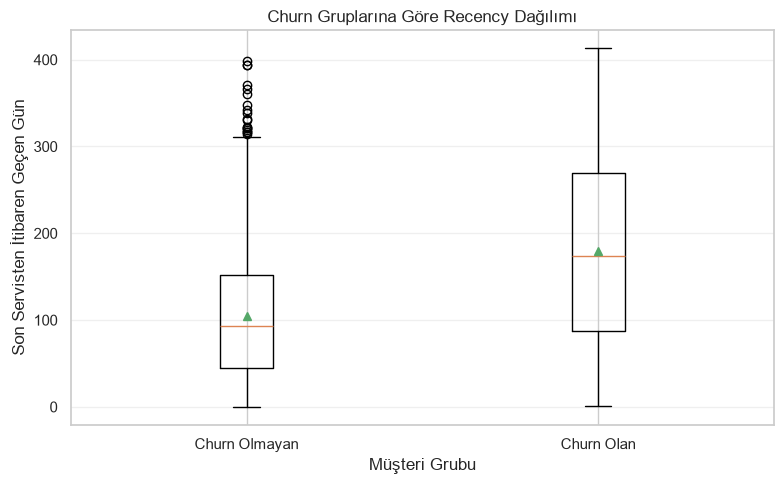

In [4]:
import matplotlib.pyplot as plt

# Churn gruplarına göre recency değerleri
recency_churn_0 = musteri_analiz.loc[
    musteri_analiz["churn"] == 0, "recency"
]

recency_churn_1 = musteri_analiz.loc[
    musteri_analiz["churn"] == 1, "recency"
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [recency_churn_0, recency_churn_1],
    tick_labels=["Churn Olmayan", "Churn Olan"],
    showmeans=True
)

ax.set_title("Churn Gruplarına Göre Recency Dağılımı")
ax.set_ylabel("Son Servisten İtibaren Geçen Gün")
ax.set_xlabel("Müşteri Grubu")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Grafiği kaydet
GRAFIK_DIR = ANALIZ_DIR / "grafikler"
GRAFIK_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    GRAFIK_DIR / "eda_recency_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Churn gruplarına göre recency dağılımı

recency_ozet = (
    musteri_analiz
    .groupby("churn")["recency"]
    .agg(
        ["count", "min", "median", "mean", "max"]
    )
)

recency_ozet["q1"] = (
    musteri_analiz.groupby("churn")["recency"].quantile(0.25)
)

recency_ozet["q3"] = (
    musteri_analiz.groupby("churn")["recency"].quantile(0.75)
)

recency_ozet = recency_ozet[
    ["count", "min", "q1", "median", "q3", "mean", "max"]
].round(2)

display(recency_ozet)

,count,min,q1,median,q3,mean,max
churn,,,,,,,
0,3316,0,45.0,93.0,152.00,104.31,399
1,658,1,87.0,174.0,269.75,179.95,413


**NOT:** Her iki grubun dağılımları bir miktar örtüşse de churn olan grubun recency değerleri genel olarak daha yüksek.

In [6]:
# Frequency ve Monetary değişkenlerinin churn gruplarına göre dağılımı

for degisken in ["frequency", "monetary"]:

    ozet = (
        musteri_analiz
        .groupby("churn")[degisken]
        .agg(
            count="count",
            min="min",
            q1=lambda x: x.quantile(0.25),
            median="median",
            q3=lambda x: x.quantile(0.75),
            mean="mean",
            max="max"
        )
        .round(2)
    )

    print(f"\n--- {degisken.upper()} Dağılımı ---")
    display(ozet)


--- FREQUENCY Dağılımı ---


,count,min,q1,median,q3,mean,max
churn,,,,,,,
0,3316,1,5.0,6.0,8.0,6.45,24
1,658,1,4.0,5.0,6.0,5.57,20



--- MONETARY Dağılımı ---


,count,min,q1,median,q3,mean,max
churn,,,,,,,
0,3316,-15893.88,47857.40,68645.78,98266.62,84645.07,2941493.53
1,658,-4611.95,42986.51,59950.58,81797.84,72903.99,2417638.25


**Üç değişken için ortak bulgu:**
- Recency: Churn olan müşterilerin son servis ziyaretinden itibaren geçen süre daha uzun.
- Frequency: Churn olan müşterilerin servis ziyaret sayısı daha düşük.
- Monetary: Churn olan müşterilerin gözlem dönemindeki toplam servis harcaması daha düşük.

In [7]:
# Kategorik değişkenlere göre churn oranları

kategorik_degiskenler = [
    "musteri_tipi",
    "sehir",
    "kayit_kanali",
    "arac_sayisi",
    "aktif_garantili_arac_sayisi"
]

for degisken in kategorik_degiskenler:

    ozet = (
        musteri_analiz
        .groupby(degisken, dropna=False)
        .agg(
            musteri_sayisi=("musteri_id", "nunique"),
            churn_sayisi=("churn", "sum"),
            churn_orani=("churn", "mean")
        )
    )

    ozet["churn_orani"] = (ozet["churn_orani"] * 100).round(2)

    ozet = ozet.sort_values(
        "churn_orani",
        ascending=False
    )

    print(f"\n--- {degisken.upper()} Bazında Churn ---")
    display(ozet)


--- MUSTERI_TIPI Bazında Churn ---


,musteri_sayisi,churn_sayisi,churn_orani
musteri_tipi,,,
Bireysel,3270,597,18.26
Kurumsal,704,61,8.66



--- SEHIR Bazında Churn ---


,musteri_sayisi,churn_sayisi,churn_orani
sehir,,,
ADANA,13,4,30.77
ISTANBUL,23,6,26.09
ankara,24,6,25.00
izmir,12,3,25.00
İSTANBUL,29,6,20.69
Kocaelı,10,2,20.00
Bursa,296,58,19.59
BURSA,16,3,18.75
Istanbul,16,3,18.75



--- KAYIT_KANALI Bazında Churn ---


,musteri_sayisi,churn_sayisi,churn_orani
kayit_kanali,,,
Web,850,163,19.18
Mobil Uygulama,374,71,18.98
Çağrı Merkezi,520,89,17.12
Bayi,2230,335,15.02



--- ARAC_SAYISI Bazında Churn ---


,musteri_sayisi,churn_sayisi,churn_orani
arac_sayisi,,,
1,3420,609,17.81
2,554,49,8.84



--- AKTIF_GARANTILI_ARAC_SAYISI Bazında Churn ---


,musteri_sayisi,churn_sayisi,churn_orani
aktif_garantili_arac_sayisi,,,
0,2955,552,18.68
1,992,104,10.48
2,27,2,7.41


In [8]:
# Şehir adlarını standartlaştırma

sehir_eslestirme = {
    "ADANA": "Adana",
    "Adana": "Adana",
    "İSTANBUL": "İstanbul",
    "ISTANBUL": "İstanbul",
    "Istanbul": "İstanbul",
    "istanbul": "İstanbul",
    "İstanbul": "İstanbul",
    "ankara": "Ankara",
    "ANKARA": "Ankara",
    "Ankara": "Ankara",
    "izmir": "İzmir",
    "IZMIR": "İzmir",
    "Izmir": "İzmir",
    "İzmir": "İzmir",
    "BURSA": "Bursa",
    "Bursa": "Bursa",
    "ANTALYA": "Antalya",
    "Antalya": "Antalya",
    "KOCAELİ": "Kocaeli",
    "Kocaelı": "Kocaeli",
    "Kocaeli": "Kocaeli"
}

musteri_analiz["sehir_standart"] = (
    musteri_analiz["sehir"]
    .map(sehir_eslestirme)
)

print("Eşleşmeyen şehir değerleri:")
display(
    musteri_analiz.loc[
        musteri_analiz["sehir_standart"].isna(),
        "sehir"
    ].value_counts(dropna=False)
)

print("\nStandartlaştırılmış şehir dağılımı:")
display(
    musteri_analiz["sehir_standart"].value_counts(dropna=False)
)

print("\nStandartlaştırılmış şehirlere göre churn:")
sehir_churn_ozet = (
    musteri_analiz
    .groupby("sehir_standart")
    .agg(
        musteri_sayisi=("musteri_id", "nunique"),
        churn_sayisi=("churn", "sum"),
        churn_orani=("churn", "mean")
    )
)

sehir_churn_ozet["churn_orani"] = (
    sehir_churn_ozet["churn_orani"] * 100
).round(2)

display(sehir_churn_ozet.sort_values("churn_orani", ascending=False))

Eşleşmeyen şehir değerleri:


Series([], Name: count, dtype: int64)


Standartlaştırılmış şehir dağılımı:


sehir_standart
İstanbul    1685
Ankara       676
İzmir        523
Antalya      313
Bursa        312
Kocaeli      254
Adana        211
Name: count, dtype: int64


Standartlaştırılmış şehirlere göre churn:


,musteri_sayisi,churn_sayisi,churn_orani
sehir_standart,,,
Bursa,312,61,19.55
İstanbul,1685,285,16.91
İzmir,523,88,16.83
Adana,211,35,16.59
Kocaeli,254,39,15.35
Antalya,313,48,15.34
Ankara,676,102,15.09


In [10]:

TEMIZ_VERI_DIR = OUTPUT_DIR / "temiz_veriler"
SERVIS_DOSYASI = TEMIZ_VERI_DIR / "servis_kayitlari_temiz.csv"

print("Servis dosyası:", SERVIS_DOSYASI)
print("Dosya mevcut mu?", SERVIS_DOSYASI.exists())

servis_df = pd.read_csv(
    SERVIS_DOSYASI,
    encoding="utf-8-sig"
)

servis_df["servis_tarihi"] = pd.to_datetime(
    servis_df["servis_tarihi"],
    errors="coerce"
)

# Özellik gözlem dönemi
GOZLEM_BASLANGIC = pd.Timestamp("2022-01-01")
GOZLEM_BITIS = pd.Timestamp("2025-06-30")

servis_gozlem = servis_df.loc[
    servis_df["servis_tarihi"].between(
        GOZLEM_BASLANGIC,
        GOZLEM_BITIS
    )
].copy()

print("\n--- Servis Gözlem Verisi ---")
print("Boyut:", servis_gozlem.shape)
print("Tekil servis kaydı:", servis_gozlem["kayit_id"].nunique())
print("Tarih aralığı:", servis_gozlem["servis_tarihi"].min(),
      "-", servis_gozlem["servis_tarihi"].max())

print("\nSütunlar:")
print(servis_gozlem.columns.tolist())

display(servis_gozlem.head())

Servis dosyası: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\servis_kayitlari_temiz.csv
Dosya mevcut mu? True

--- Servis Gözlem Verisi ---
Boyut: (25061, 8)
Tekil servis kaydı: 25061
Tarih aralığı: 2022-01-21 00:00:00 - 2025-06-30 00:00:00

Sütunlar:
['kayit_id', 'arac_id', 'servis_tarihi', 'servis_tipi', 'servis_merkezi', 'km', 'tutar', 'memnuniyet_puani']


,kayit_id,arac_id,servis_tarihi,servis_tipi,servis_merkezi,km,tutar,memnuniyet_puani
0,21678,503213,2023-04-26,Periyodik Bakım,SM-Ankara1,501,5319.69,5.0
1,12553,501847,2023-11-26,Periyodik Bakım,SM-Ankara1,1465,9200.00,4.0
2,29838,504408,2025-03-24,Arıza Onarım,SM-Maslak,1221,17307.98,2.0
4,28517,504221,2025-05-09,Periyodik Bakım,SM-Maslak,1881,5716.90,4.0
6,391,500063,2024-04-19,Periyodik Bakım,SM-Kadıköy,1455,11526.30,4.0


In [11]:


ANALIZ_DIR.mkdir(parents=True, exist_ok=True)

SERVIS_GOZLEM_CSV = ANALIZ_DIR / "servis_gozlem.csv"

servis_gozlem.to_csv(
    SERVIS_GOZLEM_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Servis gözlem verisi kaydedildi.")
print("Dosya:", SERVIS_GOZLEM_CSV)
print("Kayıt sayısı:", len(servis_gozlem))
print("Dosya mevcut mu?", SERVIS_GOZLEM_CSV.exists())

Servis gözlem verisi kaydedildi.
Dosya: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\servis_gozlem.csv
Kayıt sayısı: 25061
Dosya mevcut mu? True


In [12]:

ARAC_DOSYASI = TEMIZ_VERI_DIR / "araclar_temiz.csv"

print("Araç dosyası:", ARAC_DOSYASI)
print("Dosya mevcut mu?", ARAC_DOSYASI.exists())

arac_df = pd.read_csv(
    ARAC_DOSYASI,
    encoding="utf-8-sig"
)

print("\n--- Araç Verisi ---")
print("Boyut:", arac_df.shape)
print("Sütunlar:", arac_df.columns.tolist())
print("Tekil araç:", arac_df["arac_id"].nunique())
print("Eksik değerler:")
display(arac_df.isna().sum())

display(arac_df.head())

Araç dosyası: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\araclar_temiz.csv
Dosya mevcut mu? True

--- Araç Verisi ---
Boyut: (4786, 8)
Sütunlar: ['arac_id', 'musteri_id', 'marka', 'model', 'model_yili', 'satin_alma_tarihi', 'garanti_bitis_tarihi', 'ilk_km']
Tekil araç: 4786
Eksik değerler:


arac_id                 0
musteri_id              0
marka                   0
model                   0
model_yili              0
satin_alma_tarihi       0
garanti_bitis_tarihi    0
ilk_km                  0
dtype: int64

,arac_id,musteri_id,marka,model,model_yili,satin_alma_tarihi,garanti_bitis_tarihi,ilk_km
0,500001,100001,Marka-A,A-Sedan,2013,2013-12-02,2018-12-01,9
1,500002,100002,Marka-C,C-Mini,2019,2019-05-10,2024-05-08,15
2,500003,100003,Marka-A,A-SUV,2017,2017-07-08,2022-07-07,0
3,500004,100004,Marka-B,B-Hatch,2023,2023-08-27,2026-08-26,25
4,500005,100005,Marka-A,A-Sedan,2014,2014-05-21,2017-05-20,47


In [13]:
# Servis kayıtlarını müşteri bilgisiyle eşleştirme

servis_musteri = servis_gozlem.merge(
    arac_df[["arac_id", "musteri_id"]],
    on="arac_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("--- Eşleştirme Kontrolü ---")
print("Servis gözlem kayıt sayısı:", len(servis_gozlem))
print("Birleştirme sonrası kayıt sayısı:", len(servis_musteri))

print("\nEşleşme durumu:")
display(servis_musteri["_merge"].value_counts())

print(
    "\nEşleşmeyen servis kaydı:",
    (servis_musteri["_merge"] == "left_only").sum()
)

print(
    "Eksik müşteri ID:",
    servis_musteri["musteri_id"].isna().sum()
)

# Kontroller olumluysa geçici eşleştirme sütununu kaldır
servis_musteri.drop(columns="_merge", inplace=True)

display(servis_musteri.head())

--- Eşleştirme Kontrolü ---
Servis gözlem kayıt sayısı: 25061
Birleştirme sonrası kayıt sayısı: 25061

Eşleşme durumu:


_merge
both          25061
left_only         0
right_only        0
Name: count, dtype: int64


Eşleşmeyen servis kaydı: 0
Eksik müşteri ID: 0


C:\Users\ASUS\AppData\Local\Temp\ipykernel_37104\3496431883.py:29: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  servis_musteri.drop(columns="_merge", inplace=True)


,kayit_id,arac_id,servis_tarihi,servis_tipi,servis_merkezi,km,tutar,memnuniyet_puani,musteri_id
0,21678,503213,2023-04-26,Periyodik Bakım,SM-Ankara1,501,5319.69,5.0,102814
1,12553,501847,2023-11-26,Periyodik Bakım,SM-Ankara1,1465,9200.00,4.0,101620
2,29838,504408,2025-03-24,Arıza Onarım,SM-Maslak,1221,17307.98,2.0,103874
3,28517,504221,2025-05-09,Periyodik Bakım,SM-Maslak,1881,5716.90,4.0,103707
4,391,500063,2024-04-19,Periyodik Bakım,SM-Kadıköy,1455,11526.30,4.0,100054


In [14]:
# Müşteri bazında memnuniyet özeti

musteri_memnuniyet = (
    servis_musteri
    .groupby("musteri_id")
    .agg(
        toplam_servis_sayisi=("kayit_id", "count"),
        puanli_servis_sayisi=("memnuniyet_puani", "count"),
        eksik_puan_sayisi=("memnuniyet_puani", lambda x: x.isna().sum()),
        ortalama_memnuniyet=("memnuniyet_puani", "mean"),
        medyan_memnuniyet=("memnuniyet_puani", "median")
    )
    .reset_index()
)

musteri_memnuniyet[
    ["ortalama_memnuniyet", "medyan_memnuniyet"]
] = musteri_memnuniyet[
    ["ortalama_memnuniyet", "medyan_memnuniyet"]
].round(2)

print("--- Müşteri Memnuniyet Özeti ---")
print("Müşteri sayısı:", musteri_memnuniyet["musteri_id"].nunique())
print("Tablo boyutu:", musteri_memnuniyet.shape)

display(musteri_memnuniyet.head())

# CSV olarak kaydet
MEMNUNIYET_CSV = ANALIZ_DIR / "musteri_memnuniyet_ozeti.csv"

musteri_memnuniyet.to_csv(
    MEMNUNIYET_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("\nDosya kaydedildi:", MEMNUNIYET_CSV)
print("Dosya mevcut mu?", MEMNUNIYET_CSV.exists())

--- Müşteri Memnuniyet Özeti ---
Müşteri sayısı: 3974
Tablo boyutu: (3974, 6)


,musteri_id,toplam_servis_sayisi,puanli_servis_sayisi,eksik_puan_sayisi,ortalama_memnuniyet,medyan_memnuniyet
0,100001,5,3,2,4.33,4.0
1,100002,11,7,4,3.57,4.0
2,100003,7,7,0,4.00,4.0
3,100004,2,2,0,4.00,4.0
4,100005,4,3,1,4.00,4.0



Dosya kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\musteri_memnuniyet_ozeti.csv
Dosya mevcut mu? True


In [15]:
# Churn tablosuna müşteri memnuniyet bilgilerini ekleme

musteri_eda = musteri_analiz.merge(
    musteri_memnuniyet,
    on="musteri_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("--- Birleştirme Kontrolü ---")
print("Önceki müşteri sayısı:", len(musteri_analiz))
print("Birleştirme sonrası:", len(musteri_eda))

print("\nEşleşme durumu:")
display(musteri_eda["_merge"].value_counts())

# Eşleşmeyen müşterilerde servis özeti bulunmayabilir.
musteri_eda = musteri_eda.drop(columns="_merge")

print("\nMemnuniyet özeti bulunmayan müşteri:")
print(musteri_eda["ortalama_memnuniyet"].isna().sum())

print("\nMemnuniyet özeti bulunan müşteri:")
print(musteri_eda["ortalama_memnuniyet"].notna().sum())

# Birleştirilmiş tabloyu kaydet
MUSTERI_EDA_CSV = ANALIZ_DIR / "musteri_analiz_memnuniyet.csv"

musteri_eda.to_csv(
    MUSTERI_EDA_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("\nDosya kaydedildi:", MUSTERI_EDA_CSV)
print("Dosya mevcut mu?", MUSTERI_EDA_CSV.exists())
print("Son tablo boyutu:", musteri_eda.shape)

display(musteri_eda.head())

--- Birleştirme Kontrolü ---
Önceki müşteri sayısı: 3974
Birleştirme sonrası: 3974

Eşleşme durumu:


_merge
both          3974
left_only        0
right_only       0
Name: count, dtype: int64


Memnuniyet özeti bulunmayan müşteri:
47

Memnuniyet özeti bulunan müşteri:
3927

Dosya kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\musteri_analiz_memnuniyet.csv
Dosya mevcut mu? True
Son tablo boyutu: (3974, 24)


,musteri_id,sehir,musteri_tipi,kayit_kanali,son_servis_tarihi,frequency,monetary,recency,arac_sayisi,ortalama_model_yili,...,ilk_geri_bildirim_tarihi,son_geri_bildirim_tarihi,hedef_donem_servis_sayisi,churn,sehir_standart,toplam_servis_sayisi,puanli_servis_sayisi,eksik_puan_sayisi,ortalama_memnuniyet,medyan_memnuniyet
0,102288,Ankara,Bireysel,Bayi,2024-12-02,4,9935.32,210,1,2023.0,...,NaT,NaT,2,0,Ankara,4,3,1,4.33,5.0
1,103065,Bursa,Bireysel,Bayi,2024-10-10,4,22567.74,263,1,2016.0,...,NaT,NaT,1,0,Bursa,4,3,1,3.33,3.0
2,103404,İstanbul,Bireysel,Bayi,2025-06-20,4,47712.88,10,1,2024.0,...,2023-09-23,2023-09-23,3,0,İstanbul,4,3,1,4.00,4.0
3,102505,İstanbul,Bireysel,Bayi,2025-01-13,7,73175.03,168,1,2015.0,...,NaT,NaT,2,0,İstanbul,7,5,2,4.40,5.0
4,102599,Kocaeli,Bireysel,Bayi,2025-03-18,7,85006.86,104,1,2018.0,...,NaT,NaT,3,0,Kocaeli,7,6,1,4.00,4.0


In [16]:
# Ortalama memnuniyet puanı eksik olan müşterileri inceleme

puani_eksik_musteriler = musteri_eda.loc[
    musteri_eda["ortalama_memnuniyet"].isna(),
    [
        "musteri_id",
        "churn",
        "toplam_servis_sayisi",
        "puanli_servis_sayisi",
        "eksik_puan_sayisi"
    ]
].copy()

print("Puanı eksik müşteri sayısı:", len(puani_eksik_musteriler))

print("\nServis ve puan durumları:")
display(
    puani_eksik_musteriler[
        ["toplam_servis_sayisi", "puanli_servis_sayisi", "eksik_puan_sayisi"]
    ].describe()
)

print("\nPuanı eksik müşterilerin servis durumları:")
display(
    puani_eksik_musteriler[
        ["toplam_servis_sayisi", "puanli_servis_sayisi", "eksik_puan_sayisi"]
    ].value_counts().reset_index(name="musteri_sayisi")
)

print("\nİlk 10 müşteri:")
display(puani_eksik_musteriler.head(10))

Puanı eksik müşteri sayısı: 47

Servis ve puan durumları:


,toplam_servis_sayisi,puanli_servis_sayisi,eksik_puan_sayisi
count,47.000000,47.0,47.000000
mean,1.446809,0.0,1.446809
std,1.017425,0.0,1.017425
min,1.000000,0.0,1.000000
25%,1.000000,0.0,1.000000
50%,1.000000,0.0,1.000000
75%,1.000000,0.0,1.000000
max,6.000000,0.0,6.000000



Puanı eksik müşterilerin servis durumları:


,toplam_servis_sayisi,puanli_servis_sayisi,eksik_puan_sayisi,musteri_sayisi
0,1,0,1,36
1,2,0,2,6
2,3,0,3,2
3,4,0,4,2
4,6,0,6,1



İlk 10 müşteri:


,musteri_id,churn,toplam_servis_sayisi,puanli_servis_sayisi,eksik_puan_sayisi
150,102234,1,1,0,1
189,102309,0,1,0,1
252,101264,0,1,0,1
254,101294,0,2,0,2
260,103416,0,1,0,1
267,101185,0,1,0,1
291,102218,1,1,0,1
485,101093,0,3,0,3
499,101527,0,1,0,1
522,102669,0,2,0,2


47 müşterinin tamamının gözlem döneminde servis kaydı var ancak hiçbir servis ziyaretinde memnuniyet puanı girilmemiş.
- 36 müşterinin 1 servis kaydı var ve puanı eksik.
- 6 müşterinin 2 servis kaydı var ve ikisinin de puanı eksik.
- Kalan 5 müşterinin 3–6 arasında servis kaydı var; hiçbirinde puan bulunmuyor.

In [18]:
# Churn gruplarına göre müşteri memnuniyeti karşılaştırması

memnuniyet_churn_ozet = (
    musteri_eda
    .groupby("churn")
    .agg(
        toplam_musteri=("musteri_id", "nunique"),
        puanli_musteri=("ortalama_memnuniyet", "count"),
        ortalama_memnuniyet=("ortalama_memnuniyet", "mean"),
        medyan_memnuniyet=("ortalama_memnuniyet", "median"),
        standart_sapma=("ortalama_memnuniyet", "std")
    )
)

memnuniyet_churn_ozet["puan_kapsama_orani"] = (
    memnuniyet_churn_ozet["puanli_musteri"]
    / memnuniyet_churn_ozet["toplam_musteri"] * 100
)

memnuniyet_churn_ozet = memnuniyet_churn_ozet.round(3)

memnuniyet_churn_ozet.index = memnuniyet_churn_ozet.index.map({
    0: "Churn Olmayan",
    1: "Churn Olan"
})

display(memnuniyet_churn_ozet)


MEMNUNIYET_CHURN_CSV = ANALIZ_DIR / "memnuniyet_churn_karsilastirmasi.csv"

memnuniyet_churn_ozet.to_csv(
    MEMNUNIYET_CHURN_CSV,
    encoding="utf-8-sig"
)

print("\nDosya kaydedildi:", MEMNUNIYET_CHURN_CSV)
print("Dosya mevcut mu?", MEMNUNIYET_CHURN_CSV.exists())

,toplam_musteri,puanli_musteri,ortalama_memnuniyet,medyan_memnuniyet,standart_sapma,puan_kapsama_orani
churn,,,,,,
Churn Olmayan,3316,3275,4.008,4.000,0.453,98.764
Churn Olan,658,652,3.793,3.775,0.478,99.088



Dosya kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\memnuniyet_churn_karsilastirmasi.csv
Dosya mevcut mu? True


- Churn olmayan müşteriler: Ortalama memnuniyet 4,008; medyan 4,000.
- Churn olan müşteriler: Ortalama memnuniyet 3,793; medyan 3,775.
- Fark: Churn olmayan müşterilerin ortalaması 0,215 puan daha yüksek.
- Puan kapsama oranı: İki grupta da birbirine çok yakın (%98,764 ve %99,088).
Bu, memnuniyet puanlarının churn durumuyla ilişkili olabileceğine dair betimsel bir bulgu. Ancak tek başına düşük memnuniyetin churn'e neden olduğunu göstermez.

In [20]:
from scipy.stats import mannwhitneyu
import pandas as pd

# Yalnızca en az bir puanlı servis kaydı bulunan müşteriler
churn_olmayan_puanlar = musteri_eda.loc[
    (musteri_eda["churn"] == 0),
    "ortalama_memnuniyet"
].dropna()

churn_olan_puanlar = musteri_eda.loc[
    (musteri_eda["churn"] == 1),
    "ortalama_memnuniyet"
].dropna()

# Mann–Whitney U testi
u_istatistigi, p_degeri = mannwhitneyu(
    churn_olmayan_puanlar,
    churn_olan_puanlar,
    alternative="two-sided"
)

# Etki büyüklüğü: rank-biserial correlation
n0 = len(churn_olmayan_puanlar)
n1 = len(churn_olan_puanlar)

rank_biserial = (2 * u_istatistigi / (n0 * n1)) - 1


memnuniyet_test_sonucu = pd.DataFrame([{
    "test": "Mann-Whitney U",
    "churn_olmayan_n": n0,
    "churn_olan_n": n1,
    "u_istatistigi": u_istatistigi,
    "p_degeri": p_degeri,
    "rank_biserial_etki": rank_biserial,
    "anlamlilik_0_05": p_degeri < 0.05
}])

display(memnuniyet_test_sonucu.round(5))


TEST_CSV = ANALIZ_DIR / "memnuniyet_churn_istatistiksel_test.csv"

memnuniyet_test_sonucu.to_csv(
    TEST_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("\nDosya kaydedildi:", TEST_CSV)
print("Dosya mevcut mu?", TEST_CSV.exists())

,test,churn_olmayan_n,churn_olan_n,u_istatistigi,p_degeri,rank_biserial_etki,anlamlilik_0_05
0,Mann-Whitney U,3275,652,1347243.0,0.0,0.26188,True



Dosya kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\memnuniyet_churn_istatistiksel_test.csv
Dosya mevcut mu? True


Müşteri bazında hesaplanan ortalama memnuniyet puanları churn gruplarına göre karşılaştırıldığında, churn olmayan müşterilerin memnuniyet ortalamasının (4,008), churn olan müşterilerden (3,793) daha yüksek olduğu görülmüştür. Mann–Whitney U testi bu farkın istatistiksel olarak anlamlı olduğunu göstermiştir (U = 1.347.243, p < 0,001). Rank-biserial korelasyon 0,262 olarak hesaplanmıştır. Bulgular, daha düşük müşteri memnuniyeti ile churn arasında ilişki olabileceğini düşündürmektedir; ancak nedensellik göstermez.

In [21]:
from pathlib import Path
import pandas as pd

# Kontrol edilecek analiz çıktıları
kontrol_dosyalari = [
    ANALIZ_DIR / "musteri_analiz_tablosu.csv",
    ANALIZ_DIR / "servis_gozlem.csv",
    ANALIZ_DIR / "musteri_memnuniyet_ozeti.csv",
    ANALIZ_DIR / "musteri_analiz_memnuniyet.csv",
    ANALIZ_DIR / "memnuniyet_churn_karsilastirmasi.csv",
    ANALIZ_DIR / "memnuniyet_churn_istatistiksel_test.csv",
    ANALIZ_DIR / "03_musteri_analiz_ve_churn_raporu.md",
    ANALIZ_DIR / "grafikler" / "eda_recency_churn.png",
]

dosya_kontrol = pd.DataFrame([
    {
        "dosya": str(dosya.relative_to(PROJECT_DIR)),
        "mevcut": dosya.exists(),
        "boyut_kb": round(dosya.stat().st_size / 1024, 2)
        if dosya.exists() else None
    }
    for dosya in kontrol_dosyalari
])

display(dosya_kontrol)

print(
    "\nEksik dosya sayısı:",
    (~dosya_kontrol["mevcut"]).sum()
)

,dosya,mevcut,boyut_kb
0,ciktilar\analiz\musteri_analiz_tablosu.csv,True,332.63
1,ciktilar\analiz\servis_gozlem.csv,True,1664.42
2,ciktilar\analiz\musteri_memnuniyet_ozeti.csv,True,87.73
3,ciktilar\analiz\musteri_analiz_memnuniyet.csv,True,421.46
4,ciktilar\analiz\memnuniyet_churn_karsilastirma...,True,0.20
5,ciktilar\analiz\memnuniyet_churn_istatistiksel...,True,0.17
6,ciktilar\analiz\03_musteri_analiz_ve_churn_rap...,True,6.95
7,ciktilar\analiz\grafikler\eda_recency_churn.png,True,85.42



Eksik dosya sayısı: 0


In [23]:
eda_rapor = r"""# 04 - Keşifsel Veri Analizi ve İş Bulguları

## 1. Analiz kapsamı

Keşifsel veri analizi, 30.06.2025 kesim tarihine kadar oluşturulan 3.974 müşterilik analiz popülasyonu üzerinden gerçekleştirilmiştir. Churn hedefi, 01.07.2025–30.06.2026 dönemindeki servis davranışına göre tanımlanmıştır.

Bu bölümde müşteri davranışları, kategorik değişkenler, memnuniyet verileri ve churn ilişkileri incelenmiştir. Bulgular betimsel niteliktedir; tek başına nedensellik göstermez.

## 2. Churn gruplarına göre RFM karşılaştırması

| Metrik | Churn olmayan ortalama | Churn olan ortalama | Churn olmayan medyan | Churn olan medyan |
|---|---:|---:|---:|---:|
| Recency (gün) | 104,31 | 179,95 | 93 | 174 |
| Frequency | 6,45 | 5,57 | 6 | 5 |
| Monetary (TL) | 84.645,07 | 72.903,99 | 68.645,78 | 59.950,58 |

Churn olan müşterilerin son servislerinden itibaren geçen süre daha uzundur. Bu grupta gözlem dönemindeki servis sayısı ve toplam servis tutarı da daha düşüktür.

Bu farklılıklar, geçmiş servis davranışlarının churn tahmininde değerlendirilebilecek aday değişkenler olduğunu göstermektedir. Ancak bunların model performansına katkısı sonraki modelleme aşamasında doğrulanmalıdır.

Monetary değişkeninde uç değerler ve negatif tutarlar bulunduğundan ortalama değerler dikkatli yorumlanmalıdır. Medyan değerler merkezi eğilimi değerlendirmek için tamamlayıcı olarak sunulmuştur.

## 3. Kategorik değişkenlere göre churn oranları

### 3.1. Müşteri tipi

| Müşteri tipi | Müşteri sayısı | Churn sayısı | Churn oranı |
|---|---:|---:|---:|
| Bireysel | 3.270 | 597 | %18,26 |
| Kurumsal | 704 | 61 | %8,66 |

Bireysel müşterilerde gözlenen churn oranı kurumsal müşterilerden yüksektir. Bu fark müşteri segmentlerinin ayrı incelenmesini ve modelleme aşamasında doğrulanmasını gerektirebilir.

### 3.2. Kayıt kanalı

| Kayıt kanalı | Müşteri sayısı | Churn sayısı | Churn oranı |
|---|---:|---:|---:|
| Web | 850 | 163 | %19,18 |
| Mobil Uygulama | 374 | 71 | %18,98 |
| Çağrı Merkezi | 520 | 89 | %17,12 |
| Bayi | 2.230 | 335 | %15,02 |

Web ve mobil uygulama kanallarından kayıt olan müşterilerde daha yüksek churn oranları gözlenmiştir. Bununla birlikte kanalın tek başına churn davranışını açıkladığı sonucuna varılamaz.

### 3.3. Araç sayısı

| Araç sayısı | Müşteri sayısı | Churn sayısı | Churn oranı |
|---|---:|---:|---:|
| 1 | 3.420 | 609 | %17,81 |
| 2 | 554 | 49 | %8,84 |

İki aracı bulunan müşterilerin churn oranı daha düşüktür. Araç sayısı, müşteri bağlılığıyla ilişkili olabilecek bir segmentasyon değişkeni olarak değerlendirilebilir.

### 3.4. Aktif garantili araç sayısı

| Aktif garantili araç sayısı | Müşteri sayısı | Churn sayısı | Churn oranı |
|---|---:|---:|---:|
| 0 | 2.955 | 552 | %18,68 |
| 1 | 992 | 104 | %10,48 |
| 2 | 27 | 2 | %7,41 |

Aktif garantili aracı bulunan müşterilerde daha düşük churn oranları gözlenmiştir. Ancak iki aktif garantili aracı bulunan grubun yalnızca 27 müşteriden oluşması nedeniyle bu grubun oranı ihtiyatlı değerlendirilmelidir.

### 3.5. Şehre göre churn

Şehir adları yazım farklılıkları giderilerek standartlaştırılmıştır. Standartlaştırma ham veri üzerinde değil, analiz tablosunda ayrı bir değişken oluşturularak gerçekleştirilmiştir.

| Şehir | Müşteri sayısı | Churn sayısı | Churn oranı |
|---|---:|---:|---:|
| Bursa | 312 | 61 | %19,55 |
| İstanbul | 1.685 | 285 | %16,91 |
| İzmir | 523 | 88 | %16,83 |
| Adana | 211 | 35 | %16,59 |
| Kocaeli | 254 | 39 | %15,35 |
| Antalya | 313 | 48 | %15,34 |
| Ankara | 676 | 102 | %15,09 |

Bursa'da en yüksek, Ankara'da en düşük churn oranı gözlenmiştir. Şehirler arasındaki müşteri sayısı farklılıkları dikkate alınmalı; bu oranlar doğrudan servis kalitesi veya şehir kaynaklı bir neden olarak yorumlanmamalıdır.

## 4. Müşteri memnuniyeti ve churn ilişkisi

Gözlem dönemindeki servis kayıtları müşteri bazında birleştirilerek her müşteri için ortalama memnuniyet puanı hesaplanmıştır.

| Churn grubu | Toplam müşteri | Puanlı müşteri | Ortalama memnuniyet | Medyan memnuniyet | Puan kapsama oranı |
|---|---:|---:|---:|---:|---:|
| Churn olmayan | 3.316 | 3.275 | 4,008 | 4,000 | %98,764 |
| Churn olan | 658 | 652 | 3,793 | 3,775 | %99,088 |

Churn olmayan müşterilerin ortalama memnuniyet puanı, churn olan müşterilerden 0,215 puan daha yüksektir.

Memnuniyet puanı bulunmayan 47 müşterinin tamamında gözlem döneminde servis kaydı bulunmasına rağmen hiçbir servis kaydında puan yer almamaktadır. Bu müşteriler sıfır puanla temsil edilmemiş; memnuniyet karşılaştırmasına dahil edilmemiştir. Her iki churn grubunda puan kapsama oranının birbirine yakın olması karşılaştırmayı destekleyen bir unsurdur.

### 4.1. İstatistiksel karşılaştırma

Müşteri bazında hesaplanan ortalama memnuniyet puanlarının dağılımlarını karşılaştırmak için Mann–Whitney U testi uygulanmıştır.

| Ölçüt | Sonuç |
|---|---:|
| Churn olmayan müşteri | 3.275 |
| Churn olan müşteri | 652 |
| U istatistiği | 1.347.243 |
| p-değeri | <0,001 |
| Rank-biserial etki büyüklüğü | 0,26188 |

Test sonucunda iki churn grubunun memnuniyet puanı dağılımları arasında istatistiksel olarak anlamlı fark bulunmuştur. Rank-biserial etki büyüklüğü, churn olmayan müşterilerin daha yüksek memnuniyet puanlarına sahip olma eğilimini göstermektedir.

Bu bulgu, düşük memnuniyet ile churn arasında ilişki olabileceğini düşündürmektedir. Ancak memnuniyetin churn'e neden olduğu sonucunu kanıtlamaz.

## 5. Veri sınırlılıkları ve yorumlama

- Memnuniyet puanları servis kayıtlarının %20,95'inde eksiktir. Eksik değerler sıfır olarak doldurulmamıştır.
- Müşteri bazındaki memnuniyet karşılaştırması yalnızca en az bir puanlı servis kaydı bulunan müşterileri kapsamaktadır.
- Servis merkezi karşılaştırmasında servis kaydı seviyesinde tekrarlı müşteri gözlemleri bulunmaktadır. Bu durum istatistiksel testlerde bağımsızlık varsayımını sınırlayabilir.
- Monetary değişkeninde negatif, sıfır ve uç değerler bulunmaktadır. İşlem türü doğrulanmadan otomatik düzeltme yapılmamıştır.
- Kategorik değişkenlere göre hesaplanan churn oranları betimseldir. Değişkenler arasındaki olası etkileşimler ve diğer faktörler kontrol edilmemiştir.
- İstatistiksel anlamlılık, iş açısından önemli büyüklükte fark veya nedensellik anlamına gelmez.

## 6. İş açısından değerlendirme

EDA sonuçları aşağıdaki alanların modelleme ve müşteri segmentasyonu aşamalarında değerlendirilmesini desteklemektedir:

1. **Servis davranışı:** Son servis tarihinden itibaren geçen süre ve servis sıklığı, churn gruplarını ayırt eden aday sinyallerdir.
2. **Müşteri segmentleri:** Müşteri tipi, araç sayısı, garanti durumu ve kayıt kanalı bazında farklı churn oranları gözlenmiştir.
3. **Memnuniyet:** Churn olan müşterilerde ortalama memnuniyet daha düşüktür. Geri bildirim verileri, riskli müşterilerin incelenmesinde tamamlayıcı bilgi sağlayabilir.

Bu bulgular tek başına kampanya veya müşteri aksiyonu belirlemek için yeterli değildir. Model sonuçları, geri bildirim içerikleri ve operasyonel koşullarla birlikte değerlendirilmelidir.

## 7. Kaydedilen analiz çıktıları

- `ciktilar/analiz/musteri_analiz_tablosu.csv`
- `ciktilar/analiz/servis_gozlem.csv`
- `ciktilar/analiz/musteri_memnuniyet_ozeti.csv`
- `ciktilar/analiz/musteri_analiz_memnuniyet.csv`
- `ciktilar/analiz/memnuniyet_churn_karsilastirmasi.csv`
- `ciktilar/analiz/memnuniyet_churn_istatistiksel_test.csv`
- `ciktilar/analiz/grafikler/eda_recency_churn.png`

Bu rapor, müşteri analiz tablosu ve churn hedefinin oluşturulmasına ilişkin 03 numaralı raporu tamamlayan keşifsel analiz dokümanıdır.
"""

EDA_RAPOR_TASLAK.write_text(eda_rapor, encoding="utf-8")

print("EDA raporu kaydedildi:", EDA_RAPOR_TASLAK)
print("Dosya mevcut mu?", EDA_RAPOR_TASLAK.exists())
print("Dosya boyutu (KB):", round(EDA_RAPOR_TASLAK.stat().st_size / 1024, 2))

EDA raporu kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\04_eda_ve_is_analizi_raporu.md
Dosya mevcut mu? True
Dosya boyutu (KB): 8.02


In [24]:
import pandas as pd

memnuniyet_karsilastirma = pd.read_csv(
    ANALIZ_DIR / "memnuniyet_churn_karsilastirmasi.csv",
    encoding="utf-8-sig"
)

memnuniyet_test = pd.read_csv(
    ANALIZ_DIR / "memnuniyet_churn_istatistiksel_test.csv",
    encoding="utf-8-sig"
)

musteri_tablo = pd.read_csv(
    ANALIZ_DIR / "musteri_analiz_tablosu.csv",
    encoding="utf-8-sig"
)

# 1. Müşteri ve churn sayısı kontrolü
print("1. MÜŞTERİ TABLOSU")
print("Toplam müşteri:", len(musteri_tablo))
print("Tekil müşteri:", musteri_tablo["musteri_id"].nunique())
print("Churn dağılımı:")
print(musteri_tablo["churn"].value_counts().sort_index())

# 2. Memnuniyet karşılaştırması
print("\n2. MEMNUNİYET KARŞILAŞTIRMASI")
display(memnuniyet_karsilastirma)

# 3. İstatistiksel test
print("\n3. İSTATİSTİKSEL TEST")
display(memnuniyet_test)

# 4. Temel tutarlılık kontrolleri
kontroller = {
    "Müşteri sayısı 3974": len(musteri_tablo) == 3974,
    "Tekil müşteri sayısı 3974": musteri_tablo["musteri_id"].nunique() == 3974,
    "Churn olmayan müşteri 3316": (musteri_tablo["churn"] == 0).sum() == 3316,
    "Churn olan müşteri 658": (musteri_tablo["churn"] == 1).sum() == 658,
    "Memnuniyet grupları toplamı 3974": (
        memnuniyet_karsilastirma["toplam_musteri"].sum() == 3974
    ),
    "Testteki örneklem sayıları tutarlı": (
        memnuniyet_test.loc[0, "churn_olmayan_n"] == 3275
        and memnuniyet_test.loc[0, "churn_olan_n"] == 652
    ),
    "Test p-değeri 0.05'ten küçük": (
        memnuniyet_test.loc[0, "p_degeri"] < 0.05
    )
}

print("\n4. KONTROL SONUÇLARI")
for kontrol, sonuc in kontroller.items():
    print(f"{'BAŞARILI' if sonuc else 'KONTROL GEREKLİ'}: {kontrol}")

print("\nBaşarılı kontrol:", sum(kontroller.values()), "/", len(kontroller))

1. MÜŞTERİ TABLOSU
Toplam müşteri: 3974
Tekil müşteri: 3974
Churn dağılımı:
churn
0    3316
1     658
Name: count, dtype: int64

2. MEMNUNİYET KARŞILAŞTIRMASI


,churn,toplam_musteri,puanli_musteri,ortalama_memnuniyet,medyan_memnuniyet,standart_sapma,puan_kapsama_orani
0,Churn Olmayan,3316,3275,4.008,4.000,0.453,98.764
1,Churn Olan,658,652,3.793,3.775,0.478,99.088



3. İSTATİSTİKSEL TEST


,test,churn_olmayan_n,churn_olan_n,u_istatistigi,p_degeri,rank_biserial_etki,anlamlilik_0_05
0,Mann-Whitney U,3275,652,1347243.0,2.155991e-26,0.261877,True



4. KONTROL SONUÇLARI
BAŞARILI: Müşteri sayısı 3974
BAŞARILI: Tekil müşteri sayısı 3974
BAŞARILI: Churn olmayan müşteri 3316
BAŞARILI: Churn olan müşteri 658
BAŞARILI: Memnuniyet grupları toplamı 3974
BAŞARILI: Testteki örneklem sayıları tutarlı
BAŞARILI: Test p-değeri 0.05'ten küçük

Başarılı kontrol: 7 / 7
